# 2단계 결함 유형 분류 모델

이진 탐지 모델이 결함 경보를 발생시킨 뒤 F1~F4 유형을 분류합니다.

- 정답 레이블: `fault_type` 1~4
- `fault_type`, `is_fault`, `time_to_fault_min`, `efficiency_loss_pct`는 입력 특징에서 제외
- 결함 발생 후 최초 이진 경보 시점을 기준으로 유형 분류
- 모델과 집계시간은 validation에서 선택하고 test에 고정 적용

행마다 유형을 바꾸기보다 경보 후 짧은 관측 구간을 모아 이벤트 단위로 분류합니다. 운영에서는 경보 즉시 임시 유형을 표시하고 데이터가 쌓이면 유형을 갱신할 수 있습니다.


## 0. 모델링 데이터와 기존 특징

앞 단계에서 생성한 152개 실시간 특징을 불러옵니다. 냉각 성능 저하와 센서 드리프트처럼 느린 변화를 구분하기 위해 과거 6시간 기준선 대비 표준화 특징을 추가합니다.


In [1]:
from pathlib import Path
import json,warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestCentroid
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score,f1_score,classification_report,confusion_matrix,ConfusionMatrixDisplay
import joblib

warnings.filterwarnings('ignore',message='FigureCanvasAgg is non-interactive.*')
pd.set_option('display.width',180);pd.set_option('display.max_columns',30);pd.set_option('display.float_format',lambda x:f'{x:,.3f}')
plt.style.use('seaborn-v0_8-whitegrid');plt.rcParams.update({'font.family':'Nanum Gothic','axes.unicode_minus':False,'font.size':9})

DATA=Path('data/modeling/realtime_event_features.csv.gz');SCHEMA=Path('data/modeling/feature_schema.json');BINARY_MODEL=Path('models/binary_fault_detector_extratrees.joblib');BINARY_CONFIG=Path('models/binary_fault_detector_config.json')
if not DATA.exists(): DATA=Path('../data/modeling/realtime_event_features.csv.gz');SCHEMA=Path('../data/modeling/feature_schema.json');BINARY_MODEL=Path('../models/binary_fault_detector_extratrees.joblib');BINARY_CONFIG=Path('../models/binary_fault_detector_config.json')
df=pd.read_csv(DATA).sort_values(['sample_event_id','relative_min']).reset_index(drop=True);schema=json.loads(SCHEMA.read_text());base_features=schema['feature_columns'];binary_model=joblib.load(BINARY_MODEL);binary_config=json.loads(BINARY_CONFIG.read_text())
assert set(['fault_type','is_fault','time_to_fault_min','efficiency_loss_pct']).isdisjoint(base_features)
print(f'행 특징: {len(base_features)}개');print('결함 이벤트:',df[df['is_fault'].eq(1)]['sample_event_id'].nunique());print('이벤트 split:',df[df['is_fault'].eq(1)].drop_duplicates('sample_event_id')['split'].value_counts().to_dict())


행 특징: 152개
결함 이벤트: 35
이벤트 split: {'train': 19, 'validation': 8, 'test': 8}


## 1. 과거 6시간 기준선 특징 추가

각 시점에서 직전 6시간의 평균과 표준편차를 계산합니다. 현재 값은 기준선 계산에서 한 칸 이동해 제외하므로 미래 정보나 자기 참조가 없습니다.

- 현재 센서의 6시간 z-score
- 15분 이동평균의 6시간 기준 z-score

이 특징은 실시간 스트림에서 과거 버퍼만으로 계산할 수 있습니다.


In [2]:
sensor_cols=['reactor_temp','reactor_pressure','feed_flow_rate','coolant_flow_rate','agitator_speed_rpm','reaction_rate','conversion_rate','selectivity','yield_pct','vibration_rms','motor_current','power_consumption_kw']
grouped=df.groupby('sample_event_id',sort=False)
new_parts=[];z_cols=[]
for col in sensor_cols:
    past_mean=grouped[col].transform(lambda x:x.shift(1).rolling(360,min_periods=120).mean())
    past_std=grouped[col].transform(lambda x:x.shift(1).rolling(360,min_periods=120).std()).replace(0,np.nan)
    z_current=f'{col}__z_6h';z_short=f'{col}__mean15_vs_6h';z_cols.extend([z_current,z_short])
    new_parts.append(pd.DataFrame({z_current:((df[col]-past_mean)/past_std).clip(-20,20).astype('float32'),z_short:((df[f'{col}__mean_15m']-past_mean)/past_std).clip(-20,20).astype('float32')}))
df=pd.concat([df,pd.concat(new_parts,axis=1)],axis=1)
train_medians=df.loc[df['split'].eq('train'),z_cols].median();df[z_cols]=df[z_cols].fillna(train_medians)
print(f'기존 특징 {len(base_features)}개 + 6시간 기준 특징 {len(z_cols)}개 = {len(base_features)+len(z_cols)}개')
print('추가 특징 결측:',int(df[z_cols].isna().sum().sum()))


기존 특징 152개 + 6시간 기준 특징 24개 = 176개
추가 특징 결측: 0


## 2. 이진 경보 시점 계산

기존 이진 모델의 확률 임계값 0.25와 3분 연속 조건을 그대로 사용합니다. 결함 유형 모델은 이진 탐지 결과를 변경하지 않습니다.


In [3]:
df['binary_probability']=binary_model.predict_proba(df[base_features])[:,1]
threshold=float(binary_config['probability_threshold']);persistence=int(binary_config['persistence_minutes'])
def first_alert(group):
    signal=group['binary_probability'].to_numpy()>=threshold
    if len(signal)<persistence:return np.nan
    sustained=np.convolve(signal,np.ones(persistence,dtype=int),mode='valid')==persistence
    starts=np.flatnonzero(sustained & np.r_[True,~sustained[:-1]])+persistence-1
    return float(group.iloc[starts[0]]['relative_min']) if len(starts) else np.nan

event_alerts=[]
for event_id,g in df[df['sample_kind'].eq('post_fault')].groupby('sample_event_id'):
    event_alerts.append({'sample_event_id':event_id,'alert_min':first_alert(g.sort_values('relative_min'))})
event_alerts=pd.DataFrame(event_alerts)
print(event_alerts['alert_min'].describe().to_string());print('미탐 이벤트:',int(event_alerts['alert_min'].isna().sum()))


count    35.000
mean     35.400
std      49.904
min       2.000
25%       2.000
50%       2.000
75%      54.000
max     188.000
미탐 이벤트: 0


## 3. 경보 이후 이벤트 특징 생성

경보 시점부터 0·15·30·60분 동안 6시간 기준 z-score의 평균과 절댓값 최대치를 계산합니다. 집계시간과 모델 후보는 validation macro F1으로 선택합니다.


 horizon_min               model  validation_accuracy  validation_macro_f1
          60 Logistic regression                0.875                0.867
          60    Nearest centroid                0.875                0.867
          30    Nearest centroid                0.750                0.750
          60         Extra Trees                0.750                0.667
          15         Extra Trees                0.625                0.600
          30 Logistic regression                0.625                0.600
          15 Logistic regression                0.625                0.575
          15    Nearest centroid                0.625                0.575
          30         Extra Trees                0.625                0.550
           0         Extra Trees                0.500                0.417
           0 Logistic regression                0.000                0.000
           0    Nearest centroid                0.000                0.000

선택: Logistic regression,

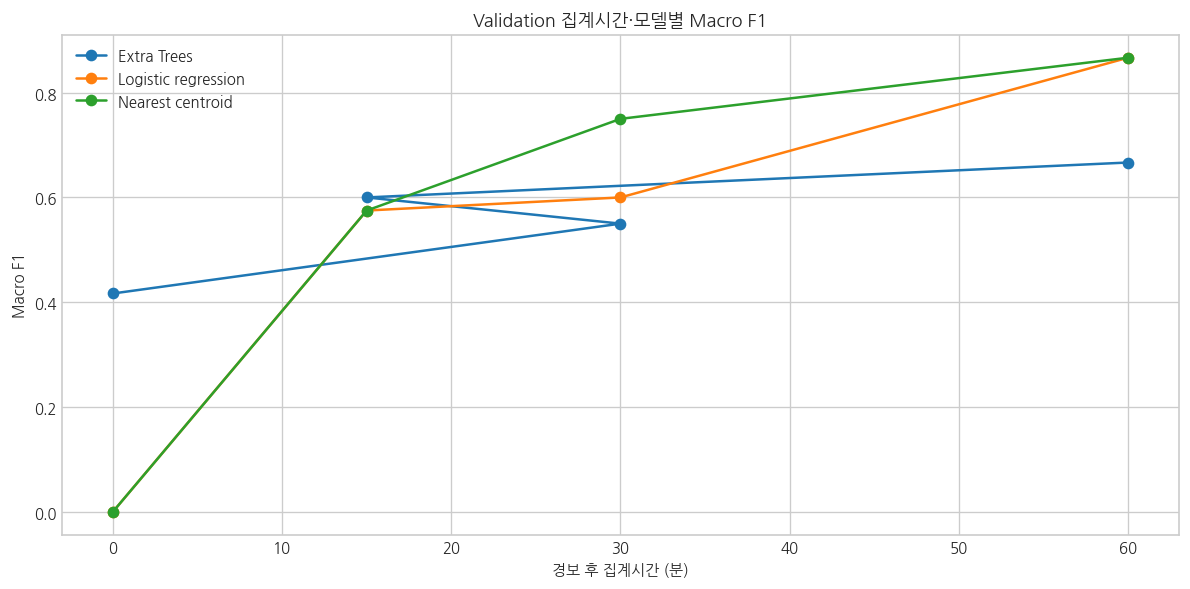

In [4]:
def build_event_features(horizon):
    rows=[]
    for event_id,g in df[df['sample_kind'].eq('post_fault')].groupby('sample_event_id'):
        g=g.sort_values('relative_min');alert=float(event_alerts.loc[event_alerts['sample_event_id'].eq(event_id),'alert_min'].iloc[0])
        if not np.isfinite(alert):continue
        window=g[g['relative_min'].between(alert,alert+horizon)]
        row={'sample_event_id':event_id,'split':g['split'].iloc[0],'operating_regime':g['operating_regime'].iloc[0],'fault_type':int(g['fault_type'].iloc[0]),'alert_min':alert,'aggregation_min':horizon,'decision_min':alert+horizon}
        for col in z_cols:
            row[f'{col}__mean']=window[col].mean();row[f'{col}__maxabs']=window[col].abs().max()
        rows.append(row)
    return pd.DataFrame(rows).fillna(0)

candidate_rows=[];candidate_models={}
for horizon in [0,15,30,60]:
    event_data=build_event_features(horizon);event_feature_cols=[c for c in event_data.columns if c.endswith('__mean') or c.endswith('__maxabs')]
    train=event_data['split'].eq('train');validation=event_data['split'].eq('validation')
    models={
      'Logistic regression':make_pipeline(StandardScaler(),LogisticRegression(C=.2,class_weight='balanced',max_iter=1000,random_state=42)),
      'Nearest centroid':make_pipeline(StandardScaler(),NearestCentroid()),
      'Extra Trees':ExtraTreesClassifier(n_estimators=500,max_depth=4,max_features='sqrt',class_weight='balanced',n_jobs=4,random_state=42),
    }
    for name,model in models.items():
        model.fit(event_data.loc[train,event_feature_cols],event_data.loc[train,'fault_type']);pred=model.predict(event_data.loc[validation,event_feature_cols])
        candidate_rows.append({'horizon_min':horizon,'model':name,'validation_accuracy':accuracy_score(event_data.loc[validation,'fault_type'],pred),'validation_macro_f1':f1_score(event_data.loc[validation,'fault_type'],pred,average='macro')});candidate_models[(horizon,name)]=(model,event_data,event_feature_cols)

comparison=pd.DataFrame(candidate_rows).sort_values(['validation_macro_f1','validation_accuracy'],ascending=False)
print(comparison.to_string(index=False))
best=comparison.iloc[0];HORIZON=int(best['horizon_min']);MODEL_NAME=str(best['model']);selected_model,event_data,event_feature_cols=candidate_models[(HORIZON,MODEL_NAME)]
print(f'\n선택: {MODEL_NAME}, 경보 후 {HORIZON}분 집계')

fig,ax=plt.subplots(figsize=(10,5))
for name,g in comparison.groupby('model'):ax.plot(g['horizon_min'],g['validation_macro_f1'],marker='o',label=name)
ax.set_title('Validation 집계시간·모델별 Macro F1');ax.set_xlabel('경보 후 집계시간 (분)');ax.set_ylabel('Macro F1');ax.legend();plt.tight_layout();plt.show()


## 4. Test 결함 유형 분류 결과

선택된 60분 집계와 로지스틱 회귀를 변경하지 않고 Test 8개 이벤트에 적용합니다. `decision_min`은 결함 시작부터 최종 유형을 확정하기까지 걸린 시간입니다.


              precision    recall  f1-score   support

           1      1.000     1.000     1.000         2
           2      1.000     1.000     1.000         2
           3      1.000     1.000     1.000         2
           4      1.000     1.000     1.000         2

    accuracy                          1.000         8
   macro avg      1.000     1.000     1.000         8
weighted avg      1.000     1.000     1.000         8

 sample_event_id operating_regime  fault_type  predicted_fault_type  confidence  alert_min  decision_min
              23                B           3                     3       0.682    107.000       167.000
              28                B           2                     2       0.984     53.000       113.000
              29                B           4                     4       0.929     63.000       123.000
              31                B           1                     1       1.000     74.000       134.000
              32                A       

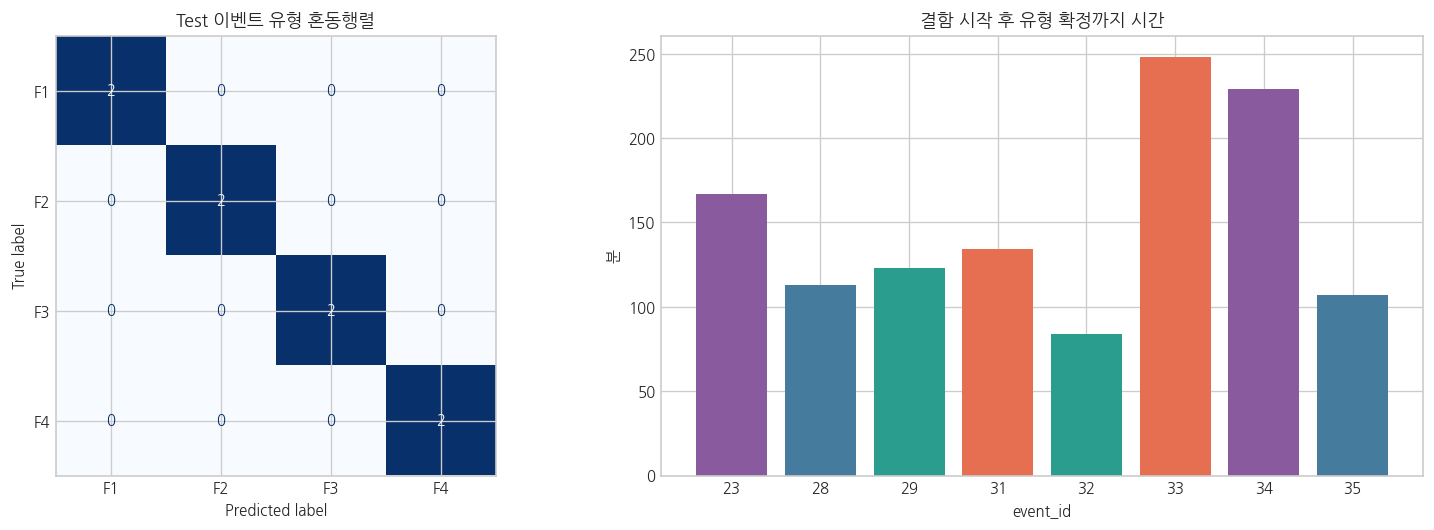

In [5]:
test=event_data[event_data['split'].eq('test')].copy();test['predicted_fault_type']=selected_model.predict(test[event_feature_cols]);prob=selected_model.predict_proba(test[event_feature_cols]);test['confidence']=prob.max(axis=1)
print(classification_report(test['fault_type'],test['predicted_fault_type'],digits=3))
print(test[['sample_event_id','operating_regime','fault_type','predicted_fault_type','confidence','alert_min','decision_min']].to_string(index=False))

test['correct']=test['fault_type'].eq(test['predicted_fault_type'])
regime_result=test.groupby('operating_regime').agg(events=('sample_event_id','count'),correct=('correct','sum'),accuracy=('correct','mean'),median_decision_min=('decision_min','median'))
print('\n레짐별 결과');print(regime_result.to_string())

fig,axes=plt.subplots(1,2,figsize=(13,4.5))
ConfusionMatrixDisplay(confusion_matrix(test['fault_type'],test['predicted_fault_type'],labels=[1,2,3,4]),display_labels=['F1','F2','F3','F4']).plot(ax=axes[0],cmap='Blues',colorbar=False);axes[0].set_title('Test 이벤트 유형 혼동행렬')
colors=test['fault_type'].map({1:'#e76f51',2:'#457b9d',3:'#8a5a9e',4:'#2a9d8f'});axes[1].bar(test['sample_event_id'].astype(str),test['decision_min'],color=colors);axes[1].set_title('결함 시작 후 유형 확정까지 시간');axes[1].set_xlabel('event_id');axes[1].set_ylabel('분')
plt.tight_layout();plt.show()


## 5. 모델과 예측 결과 저장

이 모델은 19개 train 이벤트로 학습한 초기 모델입니다. 모델 객체와 함께 6시간 기준선 특징 정의, 60분 집계 규칙과 입력 컬럼을 저장합니다.


In [6]:
MODEL_DIR=Path('models');RESULT_DIR=Path('data/modeling');MODEL_DIR.mkdir(exist_ok=True);RESULT_DIR.mkdir(parents=True,exist_ok=True)
model_path=MODEL_DIR/'fault_type_event_classifier_logistic.joblib';config_path=MODEL_DIR/'fault_type_classifier_config.json';features_path=RESULT_DIR/'fault_type_event_features.csv';prediction_path=RESULT_DIR/'test_fault_type_predictions.csv'
joblib.dump(selected_model,model_path);event_data.to_csv(features_path,index=False);test.to_csv(prediction_path,index=False)
config={'target':'fault_type','classes':{'1':'Cooling System Degradation','2':'Feed Flow Blockage','3':'Sensor Drift','4':'Mechanical Wear'},'input_feature_columns':event_feature_cols,'base_feature_count':len(base_features),'added_causal_6h_features':z_cols,'aggregation_minutes':HORIZON,'binary_alert_threshold':threshold,'binary_alert_persistence_minutes':persistence,'validation_accuracy':float(best['validation_accuracy']),'validation_macro_f1':float(best['validation_macro_f1']),'test_accuracy':float(accuracy_score(test['fault_type'],test['predicted_fault_type'])),'test_macro_f1':float(f1_score(test['fault_type'],test['predicted_fault_type'],average='macro')),'limitations':['Only 19 train, 8 validation, and 8 test events.','Perfect test accuracy is based on only two events per fault type.','Regime A test contains only two events.']}
config_path.write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding='utf-8')
print(model_path);print(config_path);print(features_path);print(prediction_path)


models/fault_type_event_classifier_logistic.joblib
models/fault_type_classifier_config.json
data/modeling/fault_type_event_features.csv
data/modeling/test_fault_type_predictions.csv


## 6. 결론

- 피처 엔지니어링은 완료됐으며 유형 분류에는 과거 6시간 기준선 특징 24개를 추가했습니다.
- 행 단위 분류보다 이진 경보 이후 이벤트 단위 집계가 더 안정적이었습니다.
- Validation에서 경보 후 60분 집계와 로지스틱 회귀가 선택됐습니다.
- Test 이벤트 8개를 모두 정확히 분류했습니다.
- F1~F4가 각각 2개씩뿐이므로 Test 100%를 일반화 성능으로 해석하면 안 됩니다.
- Regime A는 2/2, Regime B는 6/6이지만 A 표본이 너무 적어 레짐별 우열을 판단할 수 없습니다.

최종 유형 확정은 이진 경보보다 60분 늦습니다. 운영 화면에서는 경보 즉시 모델의 임시 유형과 신뢰도를 표시하고, 15·30·60분마다 갱신하는 방식이 적절합니다. 이벤트 수가 35개뿐이므로 현재 87.5%는 초기 가능성 확인 결과이며 실제 운영 성능으로 일반화하면 안 됩니다.
